# Thick-Walled Cylinder — Results, Export and Probing (v2)

This notebook extends the `example_plate_pyGmsh` workflow (the Lamé problem
of a pressurised thick-walled cylinder) by adding:

1. **Recorded results** — the run is recorded to a results file (a `.ladruno`
   on the Ladruno fork, a native `.h5` on stock openseespy) and read back as a
   `Results` object, which `results.viewer()` opens
2. **ParaView export** — the mesh and every computed field written to one
   `.vtu` with `write_vtu` from `apeGmsh.viz.VTKExport`
3. **Programmatic probing** — the `.vtu` read into pyvista and sampled at a
   point, along a line and on a cut plane, then checked against the Lamé
   closed form

The model is built from one `FEMData` snapshot: `g.mesh.partitioning.renumber()`
gives contiguous solver ids, `g.mesh.queries.get_fem_data()` takes the snapshot,
and `fem.nodes` / `fem.elements` / `fem.nodes.physical` drive the deck.

In [1]:
from apeGmsh import apeGmsh, Results, workdir
import numpy as np
from apeGmsh.opensees.emitter.live import get_ops
ops = get_ops()   # the OpenSees module apeGmsh drives

## 1 — Geometry & Mesh

Same Lamé problem as `example_plate_pyGmsh.ipynb`. After meshing, we call
`g.mesh.partitioning.renumber(method='rcm')` to get contiguous solver-ready IDs,
then `g.mesh.queries.get_fem_data()` to snapshot everything into one `FEMData` object.

In [2]:
# ============================================================
# Parameters
# ============================================================
inner_radius = 100.0    # [mm]
outer_radius = 200.0    # [mm]
lc           = 10.0     # [mm] mesh size
E   = 210.0e3           # [MPa]
nu  = 0.3
p   = 100.0             # [MPa] internal pressure
thk = 1.0               # [mm]

# ============================================================
# pyGmsh: Geometry + Mesh
# ============================================================
# save_to: g.end() writes Plate2D.h5 (and its geometry file) under outputs/
g = apeGmsh(model_name="Plate2D", verbose=False, save_to=workdir())
g.begin()

pc = g.model.geometry.add_point(0, 0, 0, lc=lc)
p1 = g.model.geometry.add_point(inner_radius, 0, 0, lc=lc)
p2 = g.model.geometry.add_point(outer_radius, 0, 0, lc=lc)
p3 = g.model.geometry.add_point(0, outer_radius, 0, lc=lc)
p4 = g.model.geometry.add_point(0, inner_radius, 0, lc=lc)

l1 = g.model.geometry.add_line(p1, p2)
l2 = g.model.geometry.add_arc(p2, pc, p3)
l3 = g.model.geometry.add_line(p3, p4)
l4 = g.model.geometry.add_arc(p4, pc, p1)

loop = g.model.geometry.add_curve_loop([l1, l2, l3, l4])
surf = g.model.geometry.add_plane_surface(loop)

pg_symY = g.physical.add(1, [l1], name="Sym_Y")
pg_symX = g.physical.add(1, [l3], name="Sym_X")
pg_pres = g.physical.add(1, [l4], name="Pressure")
pg_plat = g.physical.add(2, [surf], name="Plate")

g.mesh.generation.set_order(1)
g.mesh.generation.generate(2)

# Renumber to contiguous solver-ready IDs (RCM for bandwidth reduction)
g.mesh.partitioning.renumber(method='rcm')

# Extract the single FEMData object — this is our sole data source
# remove_orphans=True drops the arc-centre point (no element references it).
fem = g.mesh.queries.get_fem_data(dim=2, remove_orphans=True)
print(fem.info)
fem.nodes.physical.summary()

C:\Users\nmb\AppData\Local\Temp\ipykernel_64204\2532942305.py:16: UnitNotDeclaredWarning: apeGmsh(...): no consistent unit system declared (pass units='kN_m_s' or a baseUnits.systems module such as units=kN_m_s); Results and apeGmshViewer will require manual unit selection for unit conversions.
  g = apeGmsh(model_name="Plate2D", verbose=False, save_to=workdir())


1 orphan node(s) removed (not connected to any element). First: [331 (0, 0, 0)]


MeshInfo(n_nodes=330, n_elems=590, bandwidth=24, types=['tri3'])


name  n_nodes  n_elems
dim pg_tag                            
1   1          Sym_Y       11       10
    2          Sym_X       11       10
    3       Pressure       17       16
2   4          Plate      330      590

In [3]:
# ============================================================
# OpenSees: Build model, apply loads, solve
# ============================================================
# After renumber_mesh(), fem.nodes.ids and fem.elements.ids ARE
# the solver IDs — no Gmsh↔solver translation needed.
# ============================================================

ops.wipe()
ops.model("basic", "-ndm", 2, "-ndf", 2)

# --- Nodes (using FEMData iterator) ---
for nid, coords in fem.nodes.select():
    ops.node(nid, *coords)

# --- Material ---
ops.nDMaterial("ElasticIsotropic", 1, E, nu)

# --- Elements (using FEMData iterator) ---
for eid, conn in zip(fem.elements.ids, fem.elements.connectivity):
    ops.element("tri31", int(eid), *(int(n) for n in conn), thk, "PlaneStrain", 1)

# --- Boundary conditions (from fem.physical) ---
for nid in fem.nodes.physical.node_ids(pg_symY, dim=1):
    ops.fix(nid, 0, 1)   # Sym_Y: fix uy, free ux

for nid in fem.nodes.physical.node_ids(pg_symX, dim=1):
    ops.fix(nid, 1, 0)   # Sym_X: fix ux, free uy

# --- Consistent pressure loads on inner arc ---
# Edge elements from fem.physical — already in solver IDs
ops.timeSeries("Linear", 1)
ops.pattern("Plain", 1, 1)

inner = (lambda _ids_conn: {'ids': _ids_conn[0], 'connectivity': _ids_conn[1]})((fem.nodes.physical.element_ids(pg_pres, dim=1),
                                                                       fem.nodes.physical.connectivity(pg_pres, dim=1)))
inner_edges = inner['connectivity']   # (nEdge, 2)

nodal_forces = {}
for edge in inner_edges:
    n1, n2 = int(edge[0]), int(edge[1])

    # Coordinates via FEMData lookup
    x1, y1, _ = fem.nodes.coords[fem.nodes.index(n1)]
    x2, y2, _ = fem.nodes.coords[fem.nodes.index(n2)]

    Le = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
    r1 = np.sqrt(x1**2 + y1**2)
    r2 = np.sqrt(x2**2 + y2**2)

    # Traction: t = p * (x/r, y/r)
    tx1, ty1 = p * x1/r1, p * y1/r1
    tx2, ty2 = p * x2/r2, p * y2/r2

    # Consistent nodal forces: F = integral(N^T * t dGamma)
    Fx1 = (Le/6) * (2*tx1 + tx2);  Fy1 = (Le/6) * (2*ty1 + ty2)
    Fx2 = (Le/6) * (tx1 + 2*tx2);  Fy2 = (Le/6) * (ty1 + 2*ty2)

    nodal_forces.setdefault(n1, [0., 0.])
    nodal_forces.setdefault(n2, [0., 0.])
    nodal_forces[n1][0] += Fx1;  nodal_forces[n1][1] += Fy1
    nodal_forces[n2][0] += Fx2;  nodal_forces[n2][1] += Fy2

for nid, (fx, fy) in nodal_forces.items():
    ops.load(nid, fx, fy)

# --- Solve ---
ops.constraints("Transformation")
ops.numberer("RCM")
ops.system("BandGeneral")
ops.test("NormDispIncr", 1e-8, 10)
ops.algorithm("Newton")
ops.integrator("LoadControl", 1.0)
ops.analysis("Static")
ok = ops.analyze(1)
print("CONVERGED" if ok == 0 else "FAILED")

CONVERGED


Tri31 - Written by Roozbeh G. Mikola and N.Sitar, UC Berkeley


## Record results

The cell below re-runs the analysis and records it, choosing the route by
the OpenSees build the deck ran on:

- **Ladruno fork:** ``ResolvedRecorderSpec.emit_default`` records the run
  with the fork's own recorder (a ``.ladruno`` file).
- **Stock openseespy:** the cell samples the live domain after every
  converged step and writes a native results file with ``NativeWriter``.
  That file holds **displacements only**: reaction forces (and, where a
  notebook records them, line stations) are recorded on the fork only.
  ``emit_default`` cannot record this deck on a stock build without MPCO:
  its ``.out`` route needs a bridge model archive that declares ``ndm``,
  and this deck was built by hand.

The fork's file is read back with ``Results.from_ladruno``, the native one
with ``Results.from_fem``. The deck tags nodes and elements by their FEM
ids, so the FEMData snapshot is the model. The cell then checks the
recorded last step against the live domain. ``Results.viewer`` honours ``APEGMSH_SKIP_VIEWER``, so this
notebook is safe to run under nbconvert / CI without changes.

In [4]:
# --- EOS-WIRING-V2 ---
# Record the run: the fork's own recorder on the Ladruno fork, a native
# file of displacements sampled from the live domain on stock openseespy.
import contextlib
import numpy as np
from apeGmsh import Results, workdir
from apeGmsh.opensees.emitter.live import get_backend_info, get_ops
from apeGmsh.results.spec import ResolvedRecorderRecord, ResolvedRecorderSpec
from apeGmsh.results.writers import NativeWriter

OUT = workdir()

# --- copied from cell 4 ---
# ============================================================
# OpenSees: Build model, apply loads, solve
# ============================================================
# After renumber_mesh(), fem.nodes.ids and fem.elements.ids ARE
# the solver IDs — no Gmsh↔solver translation needed.
# ============================================================

ops.wipe()
ops.model("basic", "-ndm", 2, "-ndf", 2)

# --- Nodes (using FEMData iterator) ---
for nid, coords in fem.nodes.select():
    ops.node(nid, *coords)

# --- Material ---
ops.nDMaterial("ElasticIsotropic", 1, E, nu)

# --- Elements (using FEMData iterator) ---
for eid, conn in zip(fem.elements.ids, fem.elements.connectivity):
    ops.element("tri31", int(eid), *(int(n) for n in conn), thk, "PlaneStrain", 1)

# --- Boundary conditions (from fem.physical) ---
for nid in fem.nodes.physical.node_ids(pg_symY, dim=1):
    ops.fix(nid, 0, 1)   # Sym_Y: fix uy, free ux

for nid in fem.nodes.physical.node_ids(pg_symX, dim=1):
    ops.fix(nid, 1, 0)   # Sym_X: fix ux, free uy

# --- Consistent pressure loads on inner arc ---
# Edge elements from fem.physical — already in solver IDs
ops.timeSeries("Linear", 1)
ops.pattern("Plain", 1, 1)

inner = (lambda _ids_conn: {'ids': _ids_conn[0], 'connectivity': _ids_conn[1]})((fem.nodes.physical.element_ids(pg_pres, dim=1),
                                                                       fem.nodes.physical.connectivity(pg_pres, dim=1)))
inner_edges = inner['connectivity']   # (nEdge, 2)

nodal_forces = {}
for edge in inner_edges:
    n1, n2 = int(edge[0]), int(edge[1])

    # Coordinates via FEMData lookup
    x1, y1, _ = fem.nodes.coords[fem.nodes.index(n1)]
    x2, y2, _ = fem.nodes.coords[fem.nodes.index(n2)]

    Le = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
    r1 = np.sqrt(x1**2 + y1**2)
    r2 = np.sqrt(x2**2 + y2**2)

    # Traction: t = p * (x/r, y/r)
    tx1, ty1 = p * x1/r1, p * y1/r1
    tx2, ty2 = p * x2/r2, p * y2/r2

    # Consistent nodal forces: F = integral(N^T * t dGamma)
    Fx1 = (Le/6) * (2*tx1 + tx2);  Fy1 = (Le/6) * (2*ty1 + ty2)
    Fx2 = (Le/6) * (tx1 + 2*tx2);  Fy2 = (Le/6) * (ty1 + 2*ty2)

    nodal_forces.setdefault(n1, [0., 0.])
    nodal_forces.setdefault(n2, [0., 0.])
    nodal_forces[n1][0] += Fx1;  nodal_forces[n1][1] += Fy1
    nodal_forces[n2][0] += Fx2;  nodal_forces[n2][1] += Fy2

for nid, (fx, fy) in nodal_forces.items():
    ops.load(nid, fx, fy)

# --- Solve ---
ops.constraints("Transformation")
ops.numberer("RCM")
ops.system("BandGeneral")
ops.test("NormDispIncr", 1e-8, 10)
ops.algorithm("Newton")
ops.integrator("LoadControl", 1.0)
ops.analysis("Static")

# Record every FEM node the deck built.
_axes = ("x", "y", "z")[:2]
_built = set(int(n) for n in ops.getNodeTags())
_node_ids = np.asarray(
    [int(n) for n in fem.nodes.ids if int(n) in _built], dtype=np.int64)
# The deck drives the module get_ops() binds; get_backend_info() names it.
assert ops is get_ops(), "bind the deck with ops = get_ops()"
_backend = get_backend_info()
_fork = _backend.kind == "fork"
print(f"OpenSees build: {_backend.kind} ({_backend.source})")

if _fork:
    spec = ResolvedRecorderSpec(
        fem_snapshot_id=fem.snapshot_id,
        records=tuple(
            ResolvedRecorderRecord(
                category="nodes", name=kind,
                components=tuple(f"{kind}_{a}" for a in _axes),
                dt=None, n_steps=None, node_ids=_node_ids,
            )
            for kind in ("displacement", "reaction_force")
        ),
    )
    # emit_default needs a model archive on disk; the deck tags nodes and
    # elements by FEM id, so the FEMData archive is that model.
    model_h5 = OUT / "model.h5"
    fem.to_h5(str(model_h5))
    _recording = spec.emit_default(OUT / "run", model_h5=model_h5, ops=ops,
                                   overwrite=True)
else:
    _recording = contextlib.nullcontext()

_steps = []   # stock: (time, displacement) after every step


def _record_step():
    if not _fork:
        _steps.append((ops.getTime(), np.array(
            [ops.nodeDisp(int(n))[:2] for n in _node_ids])))


with _recording as run:
    ok = ops.analyze(1)
    if ok == 0:
        _record_step()
    print("CONVERGED" if ok == 0 else "FAILED")

if _fork:
    results_path = run.path
    results = Results.from_ladruno(str(results_path), model_h5=str(model_h5))
else:
    results_path = OUT / "run_native.h5"
    if results_path.exists():
        results_path.unlink()
    _u = np.stack([u for _, u in _steps])          # (T, N, ndm)
    with NativeWriter(results_path) as _nw:
        _nw.open(fem=fem, source_type="native", opensees_backend=_backend.kind)
        _sid = _nw.begin_stage(name="analysis", kind="static",
                               time=np.array([t for t, _ in _steps]))
        _nw.write_nodes(_sid, "partition_0", node_ids=_node_ids, components={
            f"displacement_{a}": _u[:, :, k] for k, a in enumerate(_axes)})
        _nw.end_stage()
    results = Results.from_fem(fem, results_path, kind="native", cache_root=OUT)
print(f"recorded -> {results_path}")

# The recorded last step is the live domain's displacement field.
_slabs = [results.nodes.get(ids=_node_ids, component=f"displacement_{a}")
          for a in _axes]
assert sorted(int(n) for n in _slabs[0].node_ids) == sorted(_node_ids.tolist())
_rec = np.column_stack([s.values[-1] for s in _slabs])
_live = np.array([ops.nodeDisp(int(n))[:2] for n in _slabs[0].node_ids])
_scale = max(float(np.abs(_live).max()), 1e-300)
assert np.allclose(_rec, _live, rtol=1e-6, atol=1e-9 * _scale), (
    "the recorded displacement disagrees with the live domain")
print(f"recorded last step matches the live domain at {len(_node_ids)} nodes")

OpenSees build: fork (C:\Program Files\Ladruno\OpenSees\bin\opensees.pyd)
CONVERGED


recorded -> outputs\run.ladruno
recorded last step matches the live domain at 330 nodes


In [5]:
# Open the recorded run in the apeGmsh ResultsViewer (subprocess, non-blocking).
# Set APEGMSH_SKIP_VIEWER=1 in the environment to skip the GUI under nbconvert / CI.
results.viewer(blocking=False)

[skip viewer] APEGMSH_SKIP_VIEWER set


In [6]:
# ============================================================
# Extract results into numpy arrays
# ============================================================
# After renumber_mesh(), fem IDs = solver IDs.
# No Gmsh↔solver translation — index directly via FEMData.
# ============================================================

nNode = fem.info.n_nodes
nElem = fem.info.n_elems

# -- Displacements --
disp = np.zeros((nNode, 2))
for i, nid in enumerate(fem.nodes.ids):
    disp[i, 0] = ops.nodeDisp(int(nid), 1)
    disp[i, 1] = ops.nodeDisp(int(nid), 2)

# -- Radial displacement --
r_nodes = np.sqrt(fem.nodes.coords[:, 0]**2 + fem.nodes.coords[:, 1]**2)
r_safe  = np.where(r_nodes > 1e-12, r_nodes, 1.0)
ur = (fem.nodes.coords[:, 0]*disp[:, 0] + fem.nodes.coords[:, 1]*disp[:, 1]) / r_safe

# -- Element stresses (CST: one constant stress per element) --
sig_xx = np.zeros(nElem)
sig_yy = np.zeros(nElem)
sig_xy = np.zeros(nElem)

for i, eid in enumerate(fem.elements.ids):
    s = ops.eleResponse(int(eid), "stresses")
    sig_xx[i] = s[0]
    sig_yy[i] = s[1]
    sig_xy[i] = s[2]

# -- Nodal-averaged stress --
conn_idx = np.array([[fem.nodes.index(n) for n in row] for row in fem.elements.connectivity])
sig_xx_nodal = np.zeros(nNode)
node_count   = np.zeros(nNode)

for e in range(nElem):
    for ln in range(3):
        nidx = conn_idx[e, ln]
        sig_xx_nodal[nidx] += sig_xx[e]
        node_count[nidx]   += 1.0

node_count[node_count == 0] = 1.0
sig_xx_nodal /= node_count

# -- Von Mises --
von_mises_elem = np.sqrt(sig_xx**2 - sig_xx*sig_yy + sig_yy**2 + 3*sig_xy**2)

print(f"u_r  range: [{ur.min():.6f}, {ur.max():.6f}] mm")
print(f"\u03c3_xx range: [{sig_xx.min():.2f}, {sig_xx.max():.2f}] MPa")
print(f"\u03c3_vm range: [{von_mises_elem.min():.2f}, {von_mises_elem.max():.2f}] MPa")

ops.wipe()
print("\nOpenSees wiped — results stored in numpy arrays.")

u_r  range: [0.057372, 0.090446] mm
σ_xx range: [-101.83, 174.50] MPa
σ_vm range: [65.26, 232.92] MPa

OpenSees wiped — results stored in numpy arrays.


## 2 — Export to ParaView

The record cell above wrote the run to a results file (a `.ladruno` on the
fork, a native `.h5` on stock), and `results` reads it back. That file holds
what was recorded: displacements (and reactions on the fork). The stresses
of section 1 came from `ops.eleResponse` and live only in numpy arrays.

To hand the mesh and every array to ParaView (or to pyvista, below), write
one `.vtu` with `write_vtu` from `apeGmsh.viz.VTKExport`, the VTK export
module. It takes the node coordinates, the 0-based connectivity, and the
point and cell fields by name.

| Call | Purpose |
|------|---------|
| `write_vtu(path, points, cells, vtk_cell_type=..., point_data=..., cell_data=...)` | Write one `.vtu` file |
| `write_vtu_series(base, points, cells, steps=[...])` | Write a time series (`.pvd` + `.vtu` files) |
| `results.viewer()` | Open the recorded run in the apeGmsh results window |
| `results.render(path, view=...)` | Write one offscreen still of the recorded run |

In [7]:
from pathlib import Path

from apeGmsh import workdir
output_dir = workdir()

# Finalize Gmsh (no longer needed — Results takes a FEMData snapshot)
g.end()

In [8]:
# Export the mesh and the section-1 fields to a .vtu for ParaView.
import pyvista as pv
from apeGmsh.viz.VTKExport import VTK_TRIANGLE, write_vtu

point_fields = {
    "Displacement": np.column_stack([disp, np.zeros(nNode)]),   # (N, 3)
    "Radial_Disp": ur,
    "Stress_XX_nodal": sig_xx_nodal,
}
cell_fields = {
    "Stress_XX": sig_xx,
    "Stress_YY": sig_yy,
    "Stress_XY": sig_xy,
    "VonMises": von_mises_elem,
}
# conn_idx (cell 8) is the tri3 connectivity as 0-based fem.nodes indices.
vtu_path = write_vtu(
    output_dir / "lame_plate_results.vtu",
    fem.nodes.coords, conn_idx,
    vtk_cell_type=VTK_TRIANGLE,
    point_data=point_fields,
    cell_data=cell_fields,
)
print(f"VTU exported: {vtu_path}")

# Read it back: the file carries the mesh and every array unchanged.
mesh = pv.read(vtu_path)
assert (mesh.n_points, mesh.n_cells) == (nNode, nElem)
assert np.allclose(mesh.points, fem.nodes.coords)
assert list(mesh.cells_dict) == [VTK_TRIANGLE]
assert np.array_equal(mesh.cells_dict[VTK_TRIANGLE], conn_idx)
for name, arr in point_fields.items():
    assert np.allclose(mesh.point_data[name], arr), name
for name, arr in cell_fields.items():
    assert np.allclose(mesh.cell_data[name], arr), name
print(f"Read back: {mesh.n_points} points, {mesh.n_cells} cells, "
      f"{len(point_fields)} point fields, {len(cell_fields)} cell fields")

VTU exported: outputs\lame_plate_results.vtu
Read back: 330 points, 590 cells, 3 point fields, 4 cell fields


## 3 — Open the recorded run

`results.viewer()` opens the recorded run in the apeGmsh results window
(contours, deformed shape, probes) in a subprocess:

```python
results.viewer(blocking=False)   # Jupyter: the notebook keeps running
results.viewer(blocking=True)    # script: waits until the window closes
```

It honours `APEGMSH_SKIP_VIEWER=1`, so the notebook runs headless under
nbconvert. The `.vtu` from section 2 opens in ParaView (File → Open), with
the stresses as cell data and the nodal fields as point data.

In [9]:
# Open the recorded run (non-blocking, so the notebook keeps running)
results.viewer(blocking=False)

[skip viewer] APEGMSH_SKIP_VIEWER set


## 4 — Programmatic probing with pyvista

The `.vtu` reads into a pyvista mesh, and pyvista samples it anywhere, not
only at the nodes:

- **Point probe:** `PolyData(point).sample(mesh)` interpolates every field at
  one coordinate.
- **Line probe:** `mesh.sample_over_line(a, b, resolution=n)` samples
  `n + 1` evenly spaced points along a line.
- **Plane probe:** `mesh.slice(normal=..., origin=...)` cuts the mesh with a
  plane.

Each sample carries a `vtkValidPointMask` array: 1 where the point fell inside
the mesh, 0 where it did not.

In [10]:
# The mesh read back from the .vtu in section 2
print(f"Loaded: {mesh.n_points} points, {mesh.n_cells} cells")
print(f"Point fields: {list(mesh.point_data.keys())}")
print(f"Cell fields:  {list(mesh.cell_data.keys())}")

Loaded: 330 points, 590 cells
Point fields: ['Displacement', 'Radial_Disp', 'Stress_XX_nodal']
Cell fields:  ['Stress_XX', 'Stress_YY', 'Stress_XY', 'VonMises']


In [11]:
# ============================================================
# Point Probe: sample at the inner wall along the x-axis
# ============================================================
# This is where the analytical solution gives maximum hoop stress.

point = pv.PolyData(np.array([[inner_radius, 0.0, 0.0]]))
at_point = point.sample(mesh)
assert at_point["vtkValidPointMask"][0] == 1, "the point is outside the mesh"
for name in ("Radial_Disp", "Stress_XX_nodal", "Stress_XX", "VonMises"):
    print(f"  {name:16s} = {at_point[name][0]: .6g}")

  Radial_Disp      =  0.090249
  Stress_XX_nodal  = -83.9285
  Stress_XX        = -89.6225
  VonMises         =  205.825


In [12]:
# ============================================================
# Line Probe: radial profile along x-axis (r = R_i to R_o)
# ============================================================
# sample_over_line returns a PolyData of resolution + 1 points with
# every field interpolated onto it.

line = mesh.sample_over_line(
    [inner_radius, 0.0, 0.0],
    [outer_radius, 0.0, 0.0],
    resolution=199,
)
valid = line["vtkValidPointMask"].astype(bool)
assert valid.all(), f"{(~valid).sum()} line samples fell outside the mesh"

r_sampled      = line.points[:, 0]   # x = r along this line
sig_xx_sampled = line["Stress_XX_nodal"]
ur_sampled     = line["Radial_Disp"]

print(f"Line probe: {line.n_points} samples, length = {outer_radius - inner_radius:.1f} mm")
print(f"  Stress_XX range: [{sig_xx_sampled.min():.2f}, {sig_xx_sampled.max():.2f}] MPa")

Line probe: 200 samples, length = 100.0 mm
  Stress_XX range: [-83.93, -2.25] MPa


In [13]:
# ============================================================
# Analytical solution (Lamé)
# ============================================================
# Along the x-axis (theta=0):
#   sigma_rr = sigma_xx = A + B/r^2
#   sigma_tt = sigma_yy = A - B/r^2
#   u_r = (1+nu)/E * [(1-2*nu)*A*r - B/r]          (plane strain)
#
# where A = p*a^2 / (b^2 - a^2),  B = -p*a^2*b^2 / (b^2 - a^2)

a, b = inner_radius, outer_radius
A_lame = p * a**2 / (b**2 - a**2)
B_lame = -p * a**2 * b**2 / (b**2 - a**2)

r_analytical = np.linspace(inner_radius, outer_radius, 500)
sig_rr_exact = A_lame + B_lame / r_analytical**2
sig_tt_exact = A_lame - B_lame / r_analytical**2
ur_exact = (1+nu)/E * ((1-2*nu)*A_lame*r_analytical - B_lame/r_analytical)

print(f"Analytical at inner wall: \u03c3_rr = {sig_rr_exact[0]:.2f}, \u03c3_tt = {sig_tt_exact[0]:.2f} MPa")
print(f"Analytical u_r: {ur_exact[0]:.6f} mm (inner), {ur_exact[-1]:.6f} mm (outer)")
print(f"Analytical at outer wall: \u03c3_rr = {sig_rr_exact[-1]:.2f}, \u03c3_tt = {sig_tt_exact[-1]:.2f} MPa")

Analytical at inner wall: σ_rr = -100.00, σ_tt = 166.67 MPa
Analytical u_r: 0.090794 mm (inner), 0.057778 mm (outer)
Analytical at outer wall: σ_rr = 0.00, σ_tt = 66.67 MPa


max |u_r(FEM) - u_r(Lamé)| / max|u_r| = 6.00e-03


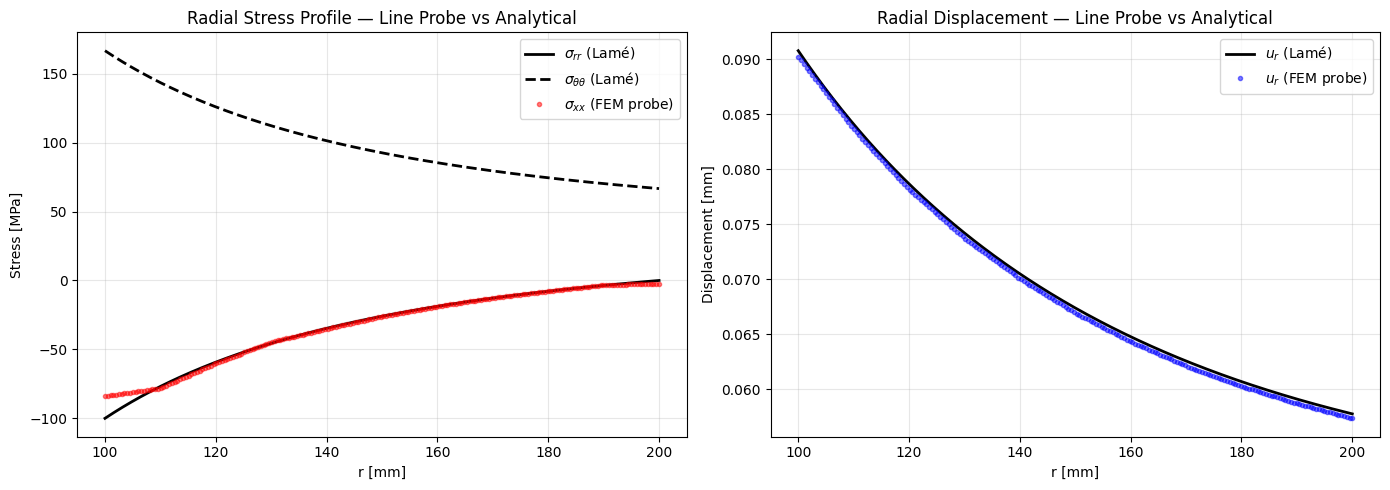


Plot saved: outputs\lame_probe_comparison.png


In [14]:
import matplotlib.pyplot as plt

# The sampled FEM radial displacement against the Lamé closed form.
ur_exact_at_samples = np.interp(r_sampled, r_analytical, ur_exact)
ur_rel_err = np.abs(ur_sampled - ur_exact_at_samples).max() / np.abs(ur_exact).max()
print(f"max |u_r(FEM) - u_r(Lamé)| / max|u_r| = {ur_rel_err:.2e}")
assert ur_rel_err < 1e-2, "the FEM radial displacement is off the Lamé solution"

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Radial stress profile: FEM probe vs analytical
ax = axes[0]
ax.plot(r_analytical, sig_rr_exact, 'k-', lw=2, label=r'$\sigma_{rr}$ (Lamé)')
ax.plot(r_analytical, sig_tt_exact, 'k--', lw=2, label=r'$\sigma_{\theta\theta}$ (Lamé)')
ax.plot(r_sampled, sig_xx_sampled, 'ro', ms=3, alpha=0.5,
        label=r'$\sigma_{xx}$ (FEM probe)')
ax.set_xlabel('r [mm]')
ax.set_ylabel('Stress [MPa]')
ax.set_title('Radial Stress Profile — Line Probe vs Analytical')
ax.legend()
ax.grid(True, alpha=0.3)

# (b) Radial displacement: FEM probe vs analytical
ax = axes[1]
ax.plot(r_analytical, ur_exact, 'k-', lw=2, label=r'$u_r$ (Lamé)')
ax.plot(r_sampled, ur_sampled, 'bo', ms=3, alpha=0.5,
        label=r'$u_r$ (FEM probe)')
ax.set_xlabel('r [mm]')
ax.set_ylabel('Displacement [mm]')
ax.set_title('Radial Displacement — Line Probe vs Analytical')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(str(output_dir / "lame_probe_comparison.png"), dpi=150)
plt.show()
print(f"\nPlot saved: {output_dir / 'lame_probe_comparison.png'}")

## 5 — Plane Probe (Slice)

Cut the mesh with a plane to inspect field values on the cross-section.
Useful for 3D models where you want to see internal stress distributions.

For this 2D problem (z=0 plane), a radial cut line is more natural,
but we demonstrate the API for completeness.

Plane slice: 31 points
Fields on slice: ['Displacement', 'Radial_Disp', 'Stress_XX_nodal']


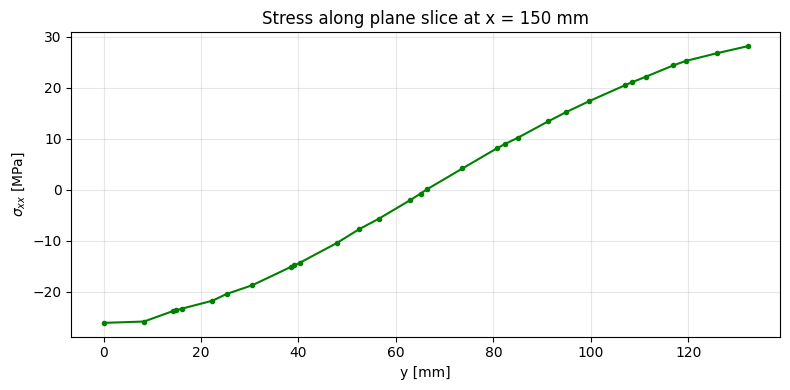

In [15]:
# ============================================================
# Plane Probe: slice at x = 150 mm (normal = x-direction)
# ============================================================
# mesh.slice returns the cut as a PolyData carrying every field.

import matplotlib.pyplot as plt

slice_x = 150.0
plane_cut = mesh.slice(normal=[1.0, 0.0, 0.0], origin=[slice_x, 0.0, 0.0])

assert plane_cut.n_points > 0, "the plane x = 150 mm missed the mesh"
print(f"Plane slice: {plane_cut.n_points} points")
print(f"Fields on slice: {list(plane_cut.point_data.keys())}")

# Every point of the cut lies on the plane x = 150 mm.
assert np.allclose(plane_cut.points[:, 0], slice_x)

slice_y = plane_cut.points[:, 1]
slice_stress = plane_cut.point_data["Stress_XX_nodal"]

order = np.argsort(slice_y)
plt.figure(figsize=(8, 4))
plt.plot(slice_y[order], slice_stress[order], 'g.-', lw=1.5)
plt.xlabel('y [mm]')
plt.ylabel(r'$\sigma_{xx}$ [MPa]')
plt.title(f'Stress along plane slice at x = {slice_x:.0f} mm')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6 — Offscreen rendering with pyvista

An offscreen `pyvista.Plotter` draws the `.vtu` mesh without opening a
window, and `screenshot` saves the PNG shown inline. For a still of the
recorded run itself, `results.render(path, view="contour")` does the same
through the apeGmsh results session.

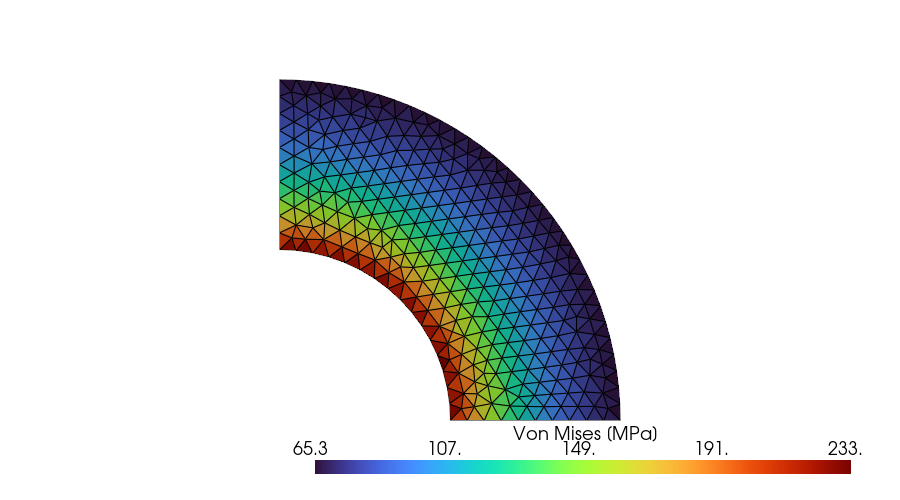

Screenshot saved: outputs\lame_vonmises.png


In [16]:
from IPython.display import Image, display

# Von Mises contour (cell data), offscreen
plotter = pv.Plotter(off_screen=True, window_size=[900, 500])
plotter.add_mesh(mesh, scalars="VonMises", cmap="turbo", show_edges=True,
                 scalar_bar_args={"title": "Von Mises [MPa]"})
plotter.view_xy()

img_path = str(output_dir / 'lame_vonmises.png')
plotter.screenshot(img_path)
plotter.close()
display(Image(filename=img_path, width=800))
print(f"Screenshot saved: {img_path}")

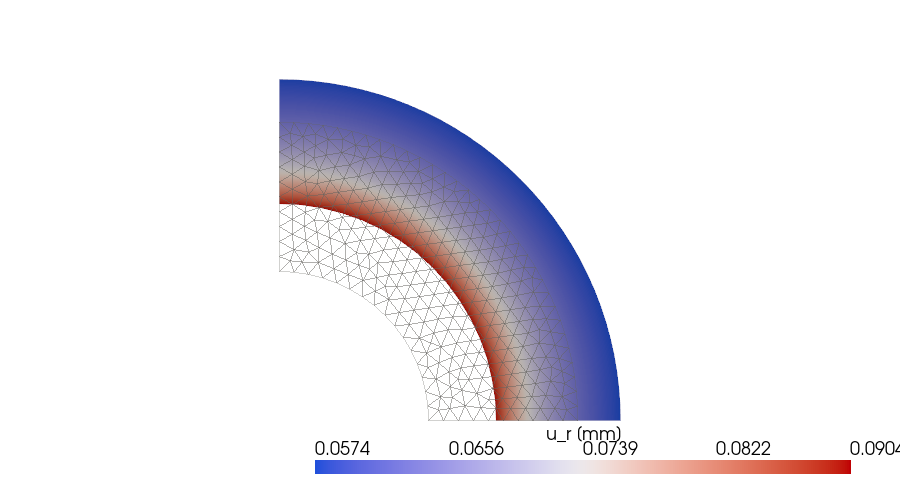

Deformed shape saved: outputs\lame_deformed.png


In [17]:
# Deformed shape (x500) with the radial displacement contour
warped = mesh.warp_by_vector("Displacement", factor=500.0)

plotter2 = pv.Plotter(off_screen=True, window_size=[900, 500])
plotter2.add_mesh(mesh, style="wireframe", color="gray", opacity=0.3)
plotter2.add_mesh(warped, scalars="Radial_Disp", cmap="coolwarm",
                  scalar_bar_args={"title": "u_r [mm]"})
plotter2.view_xy()

img_path = str(output_dir / 'lame_deformed.png')
plotter2.screenshot(img_path)
plotter2.close()
display(Image(filename=img_path, width=800))
print(f"Deformed shape saved: {img_path}")

## Summary

The full pipeline from geometry to visualization:

```
apeGmsh (geometry + mesh)
    │
    ├── g.mesh.partitioning.renumber(method='rcm')
    │
    ├── g.mesh.queries.get_fem_data()  →  FEMData   ← single data source
    │       │
    │       ├── fem.nodes / fem.elements          → OpenSees deck
    │       ├── fem.nodes.physical                → BCs & loads
    │       │
    │       └── OpenSees (solve, recorded)        → results file
    │                                               (.ladruno or native .h5)
    │
    ├── Results.from_ladruno / Results.from_fem   → results
    │       ├── results.viewer()                  → apeGmsh results window
    │       └── results.render(path)              → offscreen still
    │
    └── numpy arrays (ops.nodeDisp / eleResponse)
            │
            └── write_vtu(...)                    → .vtu for ParaView
                    │
                    └── pyvista.read
                            ├── sample / sample_over_line / slice → probes
                            └── Plotter(off_screen=True)          → stills
```

**API used in this notebook:**

| Class / Function | Purpose |
|---|---|
| `Results.from_ladruno(path, model_h5=...)` | Read a fork recorder's `.ladruno` run |
| `Results.from_fem(fem, path, kind="native")` | Read a native results file against a FEMData snapshot |
| `results.viewer(blocking=False)` | Open the recorded run (non-blocking in Jupyter) |
| `write_vtu(path, points, cells, ...)` | Export mesh + fields as one `.vtu` (`apeGmsh.viz.VTKExport`) |
| `pv.read(path)` | Read the `.vtu` into a pyvista mesh |
| `PolyData(pt).sample(mesh)` | Interpolate fields at a point |
| `mesh.sample_over_line(a, b, resolution=n)` | Sample fields along a line |
| `mesh.slice(normal=..., origin=...)` | Cut the mesh with a plane |
| `pv.Plotter(off_screen=True)` + `screenshot` | Save a PNG without a window |

**Key files generated (in `workdir()`):**
- `lame_plate_results.vtu` — mesh + all result fields, for ParaView
- `lame_probe_comparison.png` — FEM vs analytical comparison
- `lame_vonmises.png` — Von Mises contour screenshot
- `lame_deformed.png` — deformed shape screenshot